## Matplotlib

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("resultat_städad.csv")
summary_klass = pd.read_csv("summary_by_class.csv")

df.head(3), summary_klass

(    student  studietimmar  provpoäng klass  poang_per_timme
 0  Elev 065           0.7       55.0     B        78.571429
 1  Elev 059           0.0       94.0     A              NaN
 2  Elev 060           8.0      100.0     A        12.500000,
   klass  antal  medel_poäng  median_poäng  std_poäng  medel_timmar
 0     A     25        85.72          89.0      11.90          5.18
 1     B     27        73.15          70.0      13.86          4.69
 2     C     26        71.31          70.0       9.93          3.92)

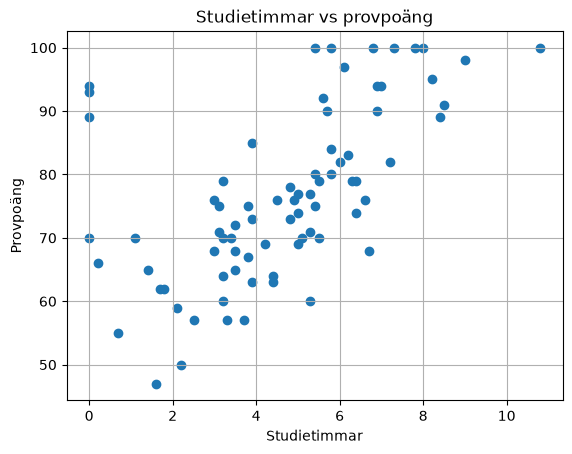

In [2]:
plt.figure()

plt.scatter(df.studietimmar, df["provpoäng"])
plt.title("Studietimmar vs provpoäng")
plt.xlabel("Studietimmar")
plt.ylabel("Provpoäng")
plt.grid(True)

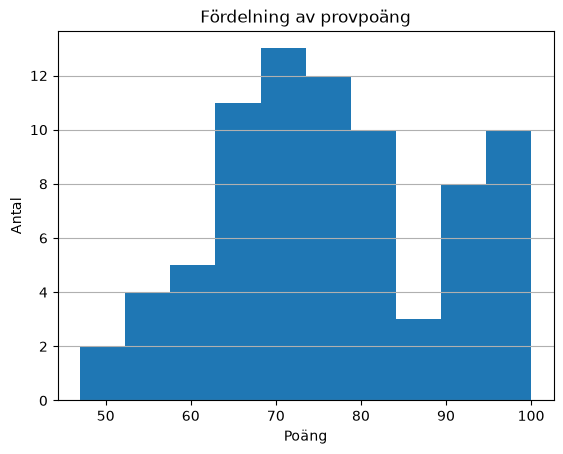

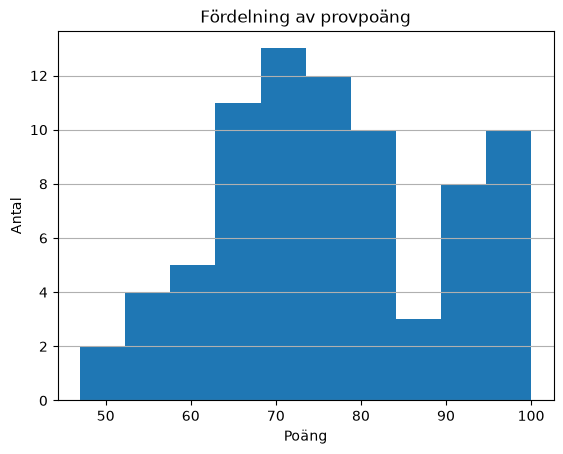

In [3]:
df.provpoäng.plot(kind="hist", bins = 10, title = "Fördelning av provpoäng")
plt.xlabel("Poäng")
plt.ylabel("Antal")
plt.grid(True, axis="y")

fig, ax = plt.subplots()

df.provpoäng.plot(kind="hist", bins = 10, title = "Fördelning av provpoäng", ax = ax )
ax.set_title("Fördelning av provpoäng")
ax.set_xlabel("Poäng")
ax.set_ylabel("Antal")
ax.grid(True, axis="y")

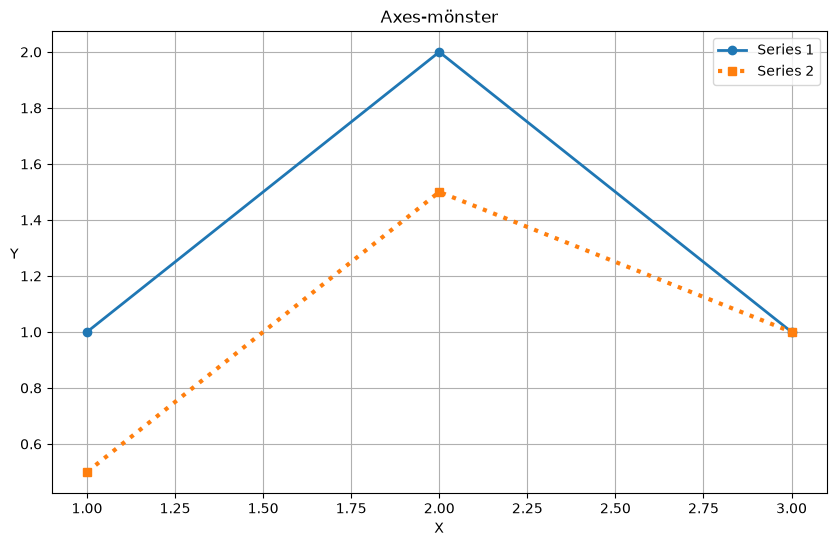

In [4]:
x = [1,2,3]
y1 = [1,2,1]
y2 = [0.5, 1.5, 1]

fig, ax = plt.subplots(figsize = (10,6))
ax.plot(x, y1, marker = "o", linestyle = "-", linewidth = 2, label = "Series 1")
ax.plot(x, y2, marker = "s", linestyle = ":", linewidth = 3, label = "Series 2" )
ax.set_title("Axes-mönster")
ax.set_xlabel("X")
ax.set_ylabel("Y", rotation = "horizontal")
ax.grid(True)
ax.legend()
#plt.tight_layout()





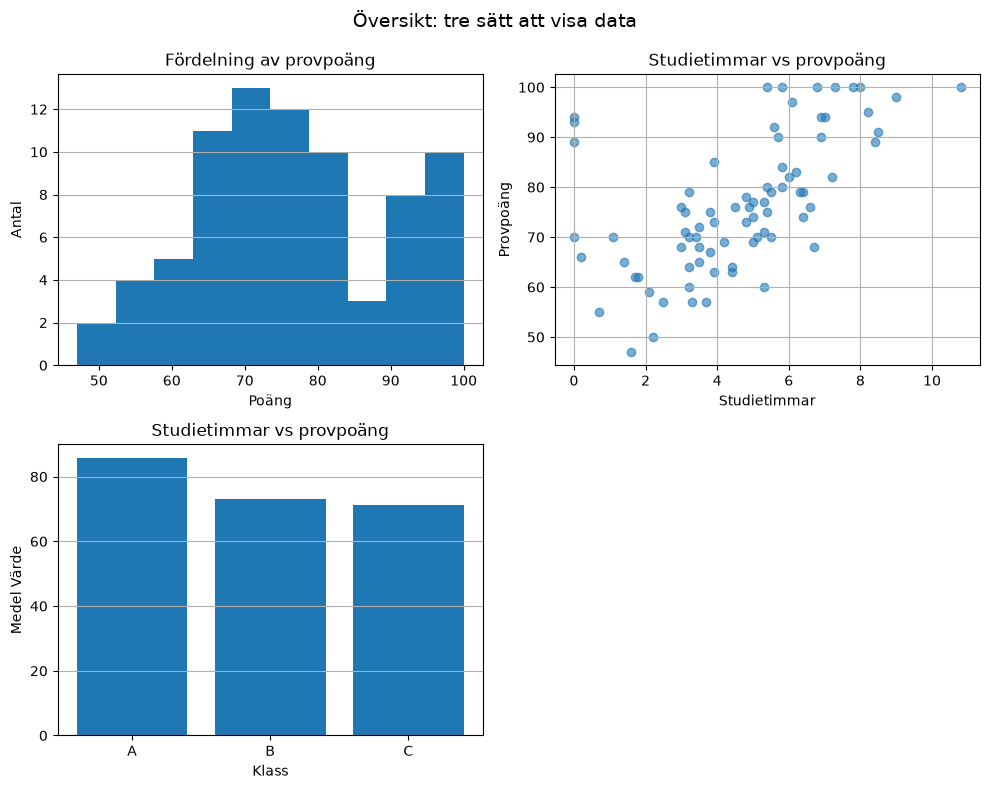

In [5]:
fig, axes = plt.subplots(2, 2, figsize =(10, 8), sharex=False, sharey=False)

axes[0,0].hist(df.provpoäng.dropna(), bins=10)
axes[0,0].set_title("Fördelning av provpoäng")
axes[0,0].set_xlabel("Poäng")
axes[0,0].set_ylabel("Antal")
axes[0,0].grid(True, axis = "y")

axes[0,1].scatter(df.studietimmar,df.provpoäng, alpha = 0.6)
axes[0,1].set_title("Studietimmar vs provpoäng")
axes[0,1].set_xlabel("Studietimmar")
axes[0,1].set_ylabel("Provpoäng")
axes[0,1].grid(True)

axes[1,0].bar(summary_klass.klass, summary_klass.medel_poäng)
axes[1,0].set_title("Studietimmar vs provpoäng")
axes[1,0].set_xlabel("Klass")
axes[1,0].set_ylabel("Medel Värde")
axes[1,0].grid(True, axis = "y")

axes[1,1].axis("off")

fig.suptitle("Översikt: tre sätt att visa data", fontsize = 14)
plt.tight_layout()
plt.subplots_adjust(top=0.9)

<function matplotlib.pyplot.tight_layout(*, pad: 'float' = 1.08, h_pad: 'float | None' = None, w_pad: 'float | None' = None, rect: 'tuple[float, float, float, float] | None' = None) -> 'None'>

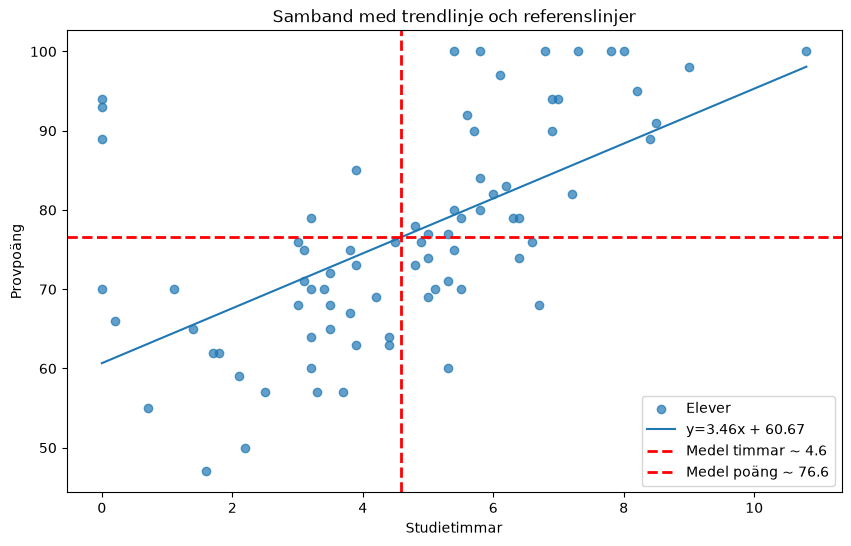

In [6]:
fig, ax = plt.subplots(figsize = (10,6))

x = df.studietimmar.to_numpy()
y = df["provpoäng"].to_numpy()

ax.scatter(x,y, alpha = 0.7, label = "Elever")

#Trendlinje
# y = kx + m
# y = mx + b
k, m = np.polyfit(x, y, 1)
ix = np.argsort(x)
ax.plot(x[ix], (k*x+m)[ix], label = rf"y={k:.2f}x + {m:.2f}")

#referenslinjer (medel)
ax.axvline (x.mean(), linestyle = "--", color = "red", linewidth=2, label = f"Medel timmar ~ {x.mean():.1f}")
ax.axhline (y.mean(), linestyle = "--", color = "red", linewidth=2, label = f"Medel poäng ~ {y.mean():.1f}")

ax.set_title("Samband med trendlinje och referenslinjer")
ax.set_xlabel("Studietimmar")
ax.set_ylabel("Provpoäng")
ax.legend(loc = "lower right")

plt.tight_layout



Text(0, 0.5, 'Poäng')

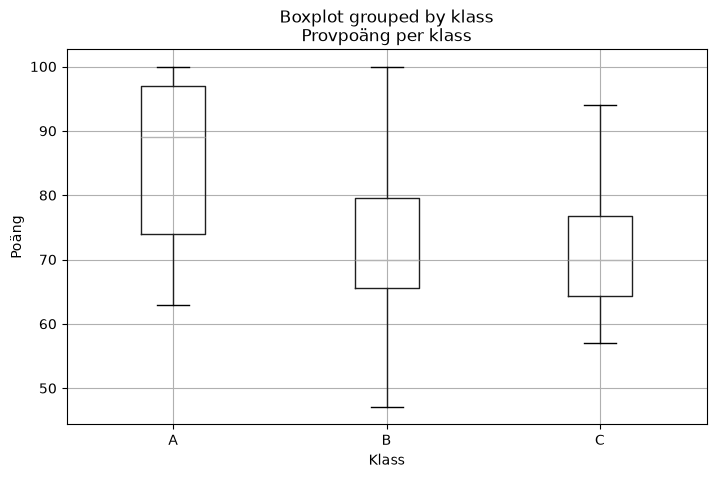

In [7]:
fig, ax = plt.subplots(figsize = (8,5))
df.boxplot(column = "provpoäng", by = "klass", ax = ax)
ax.set_title("Provpoäng per klass")
ax.set_xlabel("Klass")
ax.set_ylabel("Poäng")

<function matplotlib.pyplot.tight_layout(*, pad: 'float' = 1.08, h_pad: 'float | None' = None, w_pad: 'float | None' = None, rect: 'tuple[float, float, float, float] | None' = None) -> 'None'>

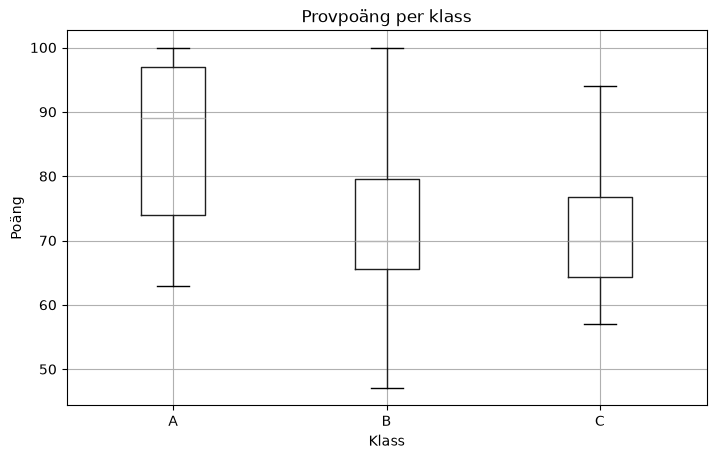

In [8]:
fig, ax = plt.subplots(figsize = (8,5))
df.boxplot(column = "provpoäng", by = "klass", ax = ax)
ax.set_title("Provpoäng per klass")
ax.set_xlabel("Klass")
ax.set_ylabel("Poäng")
plt.suptitle("")
plt.tight_layout

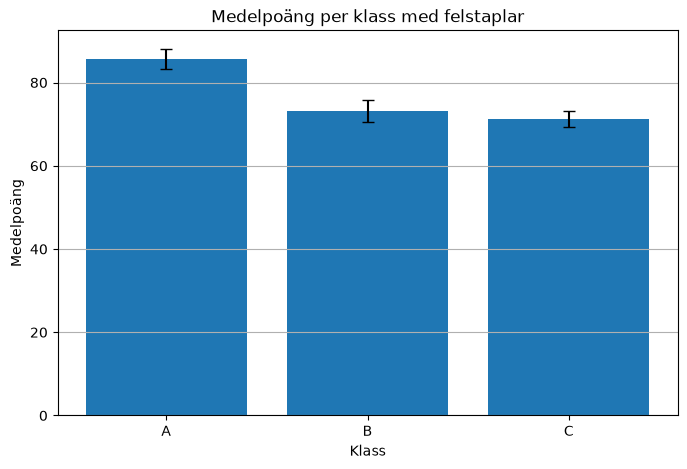

In [9]:
kategorier = summary_klass["klass"]
mean = summary_klass.medel_poäng
std = summary_klass.std_poäng
n = summary_klass.antal

se = std/np.sqrt(n)

fig, ax = plt.subplots(figsize = (8,5))
ax.bar(kategorier,mean, yerr = se, capsize = 4)
ax.set_title("Medelpoäng per klass med felstaplar")
ax.set_xlabel("Klass")
ax.set_ylabel("Medelpoäng")
ax.grid(True, axis = "y")

[None, None, None, None, None, None]

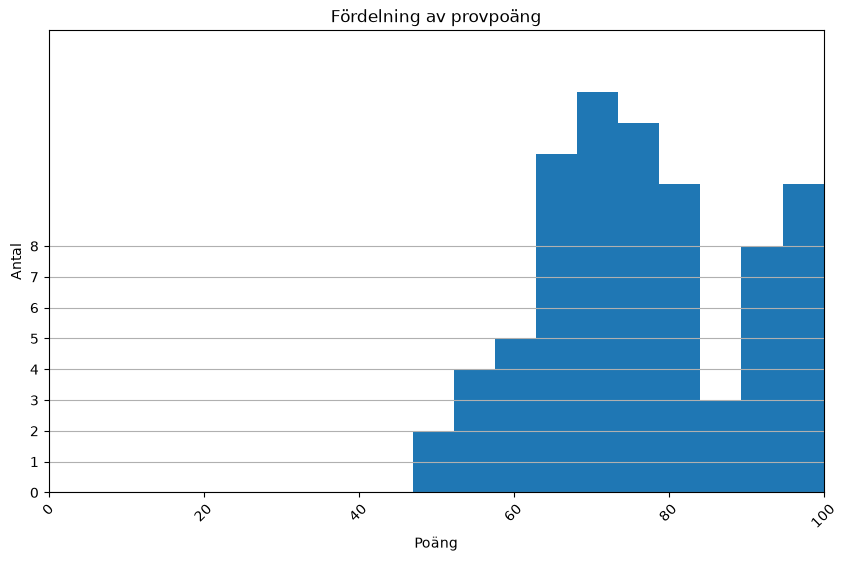

In [ ]:
fig, ax = plt.subplots(figsize = (10, 6))

df.provpoäng.plot(kind="hist", bins = 10, ax = ax )
ax.set_title("Fördelning av provpoäng")
ax.set_xlabel("Poäng")
ax.set_ylabel("Antal")
ax.grid(True, axis="y")
ax.set_xlim(0,100)
ax.set_ylim(0,15)
ax.set_yticks([0,1,2,3,4,5,6,7,8])
plt.setp(ax.get_xticklabels(), rotation = 45)